# Statistical Analysis and Match Outcome Prediction in ODI Cricket



In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

from scipy import stats
from scipy.stats import ttest_ind, chi2_contingency, f_oneway, pearsonr

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

print("All libraries imported successfully.")


All libraries imported successfully.


In [ ]:
# Load dataset
# Adjust PATH as needed for your environment
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Change path according to your file location
file_path = '/content/drive/MyDrive/final_odi_dataset.csv'

df_raw = pd.read_csv(file_path)

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Shape          : {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print(f"Memory Usage   : {df_raw.memory_usage(deep=True).sum() / 1024:.1f} KB")
print()
print("Columns:", list(df_raw.columns))


Mounted at /content/drive
DATASET OVERVIEW
Shape          : 4644 rows × 16 columns
Memory Usage   : 1736.8 KB

Columns: ['team1', 'team2', 'total_runs_team1', 'total_runs_team2', 'wickets_team1', 'wickets_team2', 'strike_rate_team1', 'strike_rate_team2', 'economy_team1', 'economy_team2', 'avg_partnership_team1', 'avg_partnership_team2', 'toss_winner', 'toss_winner_choice', 'match_venue_(stadium)', 'match_outcome']


In [ ]:
# Display sample rows
print("Sample of 30 rows from the ODI Dataset:")
df_raw.head(5)


Sample of 30 rows from the ODI Dataset:


,team1,team2,total_runs_team1,total_runs_team2,wickets_team1,wickets_team2,strike_rate_team1,strike_rate_team2,economy_team1,economy_team2,avg_partnership_team1,avg_partnership_team2,toss_winner,toss_winner_choice,match_venue_(stadium),match_outcome
0,Australia,England,185,180,9,5,66.308244,56.962025,4.568528,5.346821,0.0,0.0,Australia,bowl,Melbourne Cricket Ground,1
1,New Zealand,Pakistan,163,153,8,9,50.937500,55.839416,4.594595,4.255875,0.0,0.0,Pakistan,bowl,Lancaster Park,1
2,Australia,New Zealand,186,178,9,2,91.625616,61.805556,5.085714,7.654321,0.0,0.0,New Zealand,bat,Carisbrook,1
3,Australia,New Zealand,253,225,6,5,88.771930,78.125000,6.428571,7.228571,0.0,0.0,Australia,bat,Lancaster Park,1
4,Australia,England,179,171,4,9,63.701068,56.810631,4.609164,5.188406,0.0,0.0,England,bowl,Melbourne Cricket Ground,0


In [ ]:
# Data Preprocessing and Feature Engineering
df = df_raw.copy()
print("Working copy created. Shape:", df.shape)

# ──  Missing values ─────────────────────────────────────
print("\n--- Missing Values ---")
missing = df.isnull().sum()
print(missing)
print(f"\nTotal missing cells : {missing.sum()}")

# ──  Duplicate rows ────────────────────────────────────
n_dup = df.duplicated().sum()
print(f"\nDuplicate rows : {n_dup}")
if n_dup > 0:
    df.drop_duplicates(inplace=True)
    print(f"Duplicates removed. New shape: {df.shape}")
else:
    print("No duplicates found — dataset is clean.")


Working copy created. Shape: (4644, 16)

--- Missing Values ---
team1                    0
team2                    0
total_runs_team1         0
total_runs_team2         0
wickets_team1            0
wickets_team2            0
strike_rate_team1        0
strike_rate_team2        0
economy_team1            0
economy_team2            0
avg_partnership_team1    0
avg_partnership_team2    0
toss_winner              0
toss_winner_choice       0
match_venue_(stadium)    0
match_outcome            0
dtype: int64

Total missing cells : 0

Duplicate rows : 0
No duplicates found — dataset is clean.


In [ ]:
# ──  Engineer binary feature: did Team 1 win the toss? ─
df['toss_won_by_team1'] = (df['toss_winner'] == df['team1']).astype(int)
print("Binary toss feature 'toss_won_by_team1' created.")
print(df['toss_won_by_team1'].value_counts().rename({1:'Team1 won toss', 0:'Team2 won toss'}))

# ── 5 Encode toss_winner_choice (bat=1, field=0) ────────
df['toss_choice_encoded'] = (
    df['toss_winner_choice'].str.lower().str.strip() == 'bat'
).astype(int)
print("\nToss choice encoded (1=bat, 0=field):")
print(df['toss_choice_encoded'].value_counts())

# ──  Label-encode team names and venue ──────────────────
le_team  = LabelEncoder()
all_teams = pd.concat([df['team1'], df['team2'], df['toss_winner']]).unique()
le_team.fit(all_teams)
df['team1_enc'] = le_team.transform(df['team1'])
df['team2_enc'] = le_team.transform(df['team2'])

le_venue = LabelEncoder()
df['venue_enc'] = le_venue.fit_transform(df['match_venue_(stadium)'])

print(f"\nLabel encoding complete.")
print(f"  Unique teams  : {len(le_team.classes_)}")
print(f"  Unique venues : {len(le_venue.classes_)}")


Binary toss feature 'toss_won_by_team1' created.
toss_won_by_team1
Team1 won toss    2346
Team2 won toss    2298
Name: count, dtype: int64

Toss choice encoded (1=bat, 0=field):
toss_choice_encoded
1    2353
0    2291
Name: count, dtype: int64

Label encoding complete.
  Unique teams  : 29
  Unique venues : 251


In [ ]:
# ── Define core numerical features ────────────────────
num_features = [
    'total_runs_team1', 'total_runs_team2',
    'wickets_team1',    'wickets_team2',
    'strike_rate_team1','strike_rate_team2',
    'economy_team1',    'economy_team2',
    'avg_partnership_team1', 'avg_partnership_team2'
]

# ──  Create difference (relative performance) features ──
# These represent Team 1's ADVANTAGE over Team 2.
# Positive run_diff means Team1 outscored Team2, etc.
df['run_diff']          = df['total_runs_team1']   - df['total_runs_team2']
df['wicket_diff']       = df['wickets_team1']       - df['wickets_team2']      # negative = fewer wickets lost (better)
df['strike_rate_diff']  = df['strike_rate_team1']   - df['strike_rate_team2']
df['economy_diff']      = df['economy_team2']       - df['economy_team1']      # positive = Team2 bowls worse (Team1 advantage)
df['partnership_diff']  = df['avg_partnership_team1'] - df['avg_partnership_team2']

diff_features = ['run_diff','wicket_diff','strike_rate_diff','economy_diff','partnership_diff']

print("Difference features created:")
for f in diff_features:
    c = df[f].corr(df['match_outcome'])
    print(f"  {f:<25s}  corr with outcome = {c:+.4f}")


Difference features created:
  run_diff                   corr with outcome = +0.5089
  wicket_diff                corr with outcome = +0.7211
  strike_rate_diff           corr with outcome = +0.6430
  economy_diff               corr with outcome = +0.6480
  partnership_diff           corr with outcome = +0.4958


In [ ]:
# ──  Feature scaling ───────────────────────────────────
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[num_features] = scaler.fit_transform(df[num_features])

print("StandardScaler applied to numerical features.")
print("Scaled means (should be ~0):")
print(df_scaled[num_features].mean().round(4))
print("\nFinal processed dataset shape:", df.shape)
print("\nTarget distribution:")
vc = df['match_outcome'].value_counts()
print(f"  Team1 Wins (1): {vc[1]}  ({vc[1]/len(df)*100:.1f}%)")
print(f"  Team2 Wins (0): {vc[0]}  ({vc[0]/len(df)*100:.1f}%)")


StandardScaler applied to numerical features.
Scaled means (should be ~0):
total_runs_team1         0.0
total_runs_team2         0.0
wickets_team1           -0.0
wickets_team2            0.0
strike_rate_team1       -0.0
strike_rate_team2       -0.0
economy_team1           -0.0
economy_team2            0.0
avg_partnership_team1   -0.0
avg_partnership_team2    0.0
dtype: float64

Final processed dataset shape: (4644, 26)

Target distribution:
  Team1 Wins (1): 2442  (52.6%)
  Team2 Wins (0): 2202  (47.4%)


In [ ]:
#Descriptive Statistics
desc = df[num_features].describe().T
desc['variance'] = df[num_features].var()
desc['skewness'] = df[num_features].skew()
desc['kurtosis'] = df[num_features].kurtosis()
desc['IQR']      = df[num_features].apply(lambda x: x.quantile(0.75) - x.quantile(0.25))

print("=" * 100)
print("DESCRIPTIVE STATISTICS — NUMERICAL FEATURES")
print("=" * 100)
desc.round(3)


DESCRIPTIVE STATISTICS — NUMERICAL FEATURES


,count,mean,std,min,25%,50%,75%,max,variance,skewness,kurtosis,IQR
total_runs_team1,4644.0,205.575,62.360,4.000,165.000,206.000,246.000,476.000,3888.732,0.021,0.233,81.000
total_runs_team2,4644.0,202.776,61.167,0.000,162.000,202.000,243.000,462.000,3741.358,0.020,0.173,81.000
wickets_team1,4644.0,6.736,2.542,0.000,5.000,7.000,9.000,10.000,6.462,-0.551,-0.587,4.000
wickets_team2,4644.0,6.409,2.574,0.000,5.000,7.000,9.000,10.000,6.626,-0.383,-0.769,4.000
strike_rate_team1,4644.0,76.408,19.021,16.393,63.877,75.418,87.667,223.016,361.810,0.683,2.621,23.789
strike_rate_team2,4644.0,75.013,18.234,0.000,62.663,73.860,86.333,241.667,332.477,0.544,1.952,23.671
economy_team1,4644.0,4.735,1.109,0.750,3.987,4.660,5.409,15.167,1.229,0.611,2.183,1.423
economy_team2,4644.0,4.835,1.164,0.993,4.062,4.772,5.510,14.146,1.356,0.786,3.198,1.448
avg_partnership_team1,4644.0,10.408,11.487,0.000,0.000,9.429,15.571,133.000,131.941,2.303,12.178,15.571
avg_partnership_team2,4644.0,9.607,10.597,0.000,0.000,8.800,14.444,110.000,112.288,2.320,12.049,14.444


In [ ]:
# ──  Symmetric summary: Team1 vs Team2 side-by-side ────
print("=" * 75)
print("SYMMETRIC COMPARISON: TEAM1 vs TEAM2")
print("=" * 75)

pairs = [
    ('total_runs_team1',       'total_runs_team2'),
    ('wickets_team1',          'wickets_team2'),
    ('strike_rate_team1',      'strike_rate_team2'),
    ('economy_team1',          'economy_team2'),
    ('avg_partnership_team1',  'avg_partnership_team2'),
]

for t1, t2 in pairs:
    label = t1.replace('_team1','').replace('_',' ').title()
    m1, m2 = df[t1].mean(), df[t2].mean()
    s1, s2 = df[t1].std(),  df[t2].std()
    print(f"\n{label}")
    print(f"  Team1 — Mean: {m1:.2f}  Std: {s1:.2f}")
    print(f"  Team2 — Mean: {m2:.2f}  Std: {s2:.2f}")
    print(f"  Absolute mean difference: {abs(m1-m2):.2f}")


SYMMETRIC COMPARISON: TEAM1 vs TEAM2

Total Runs
  Team1 — Mean: 205.57  Std: 62.36
  Team2 — Mean: 202.78  Std: 61.17
  Absolute mean difference: 2.80

Wickets
  Team1 — Mean: 6.74  Std: 2.54
  Team2 — Mean: 6.41  Std: 2.57
  Absolute mean difference: 0.33

Strike Rate
  Team1 — Mean: 76.41  Std: 19.02
  Team2 — Mean: 75.01  Std: 18.23
  Absolute mean difference: 1.40

Economy
  Team1 — Mean: 4.74  Std: 1.11
  Team2 — Mean: 4.83  Std: 1.16
  Absolute mean difference: 0.10

Avg Partnership
  Team1 — Mean: 10.41  Std: 11.49
  Team2 — Mean: 9.61  Std: 10.60
  Absolute mean difference: 0.80


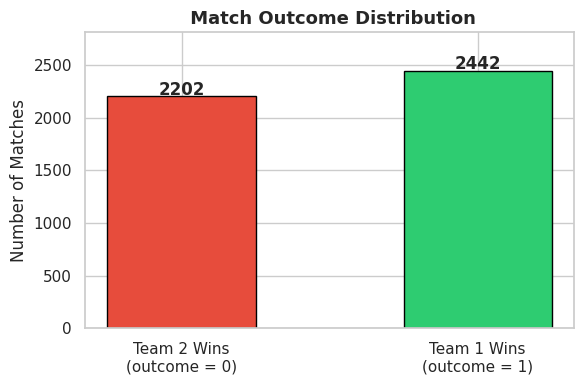

Team 1 Wins : 2442 (52.6%)
Team 2 Wins : 2202 (47.4%)


In [ ]:
# Match Outcome Distribution
fig, ax = plt.subplots(figsize=(6, 4))
vc = df['match_outcome'].value_counts()
bars = ax.bar(['Team 2 Wins\n(outcome = 0)', 'Team 1 Wins\n(outcome = 1)'],
               vc[[0, 1]].values,
               color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.5)
for bar, val in zip(bars, vc[[0, 1]].values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
            str(val), ha='center', fontsize=12, fontweight='bold')
ax.set_title(' Match Outcome Distribution', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Matches')
ax.set_ylim(0, vc.max() * 1.15)
plt.tight_layout()
plt.show()
print(f"Team 1 Wins : {vc[1]} ({vc[1]/len(df)*100:.1f}%)")
print(f"Team 2 Wins : {vc[0]} ({vc[0]/len(df)*100:.1f}%)")


**Interpretation:** The dataset is nearly balanced — approximately 52–53% Team 1 wins vs 47–48% Team 2 wins. This near-balance is ideal for classification: no significant class imbalance correction (e.g., oversampling, class weighting) is required. The slight imbalance toward Team 1 likely reflects a mild home-ground or batting-first advantage encoded in the team designation convention.

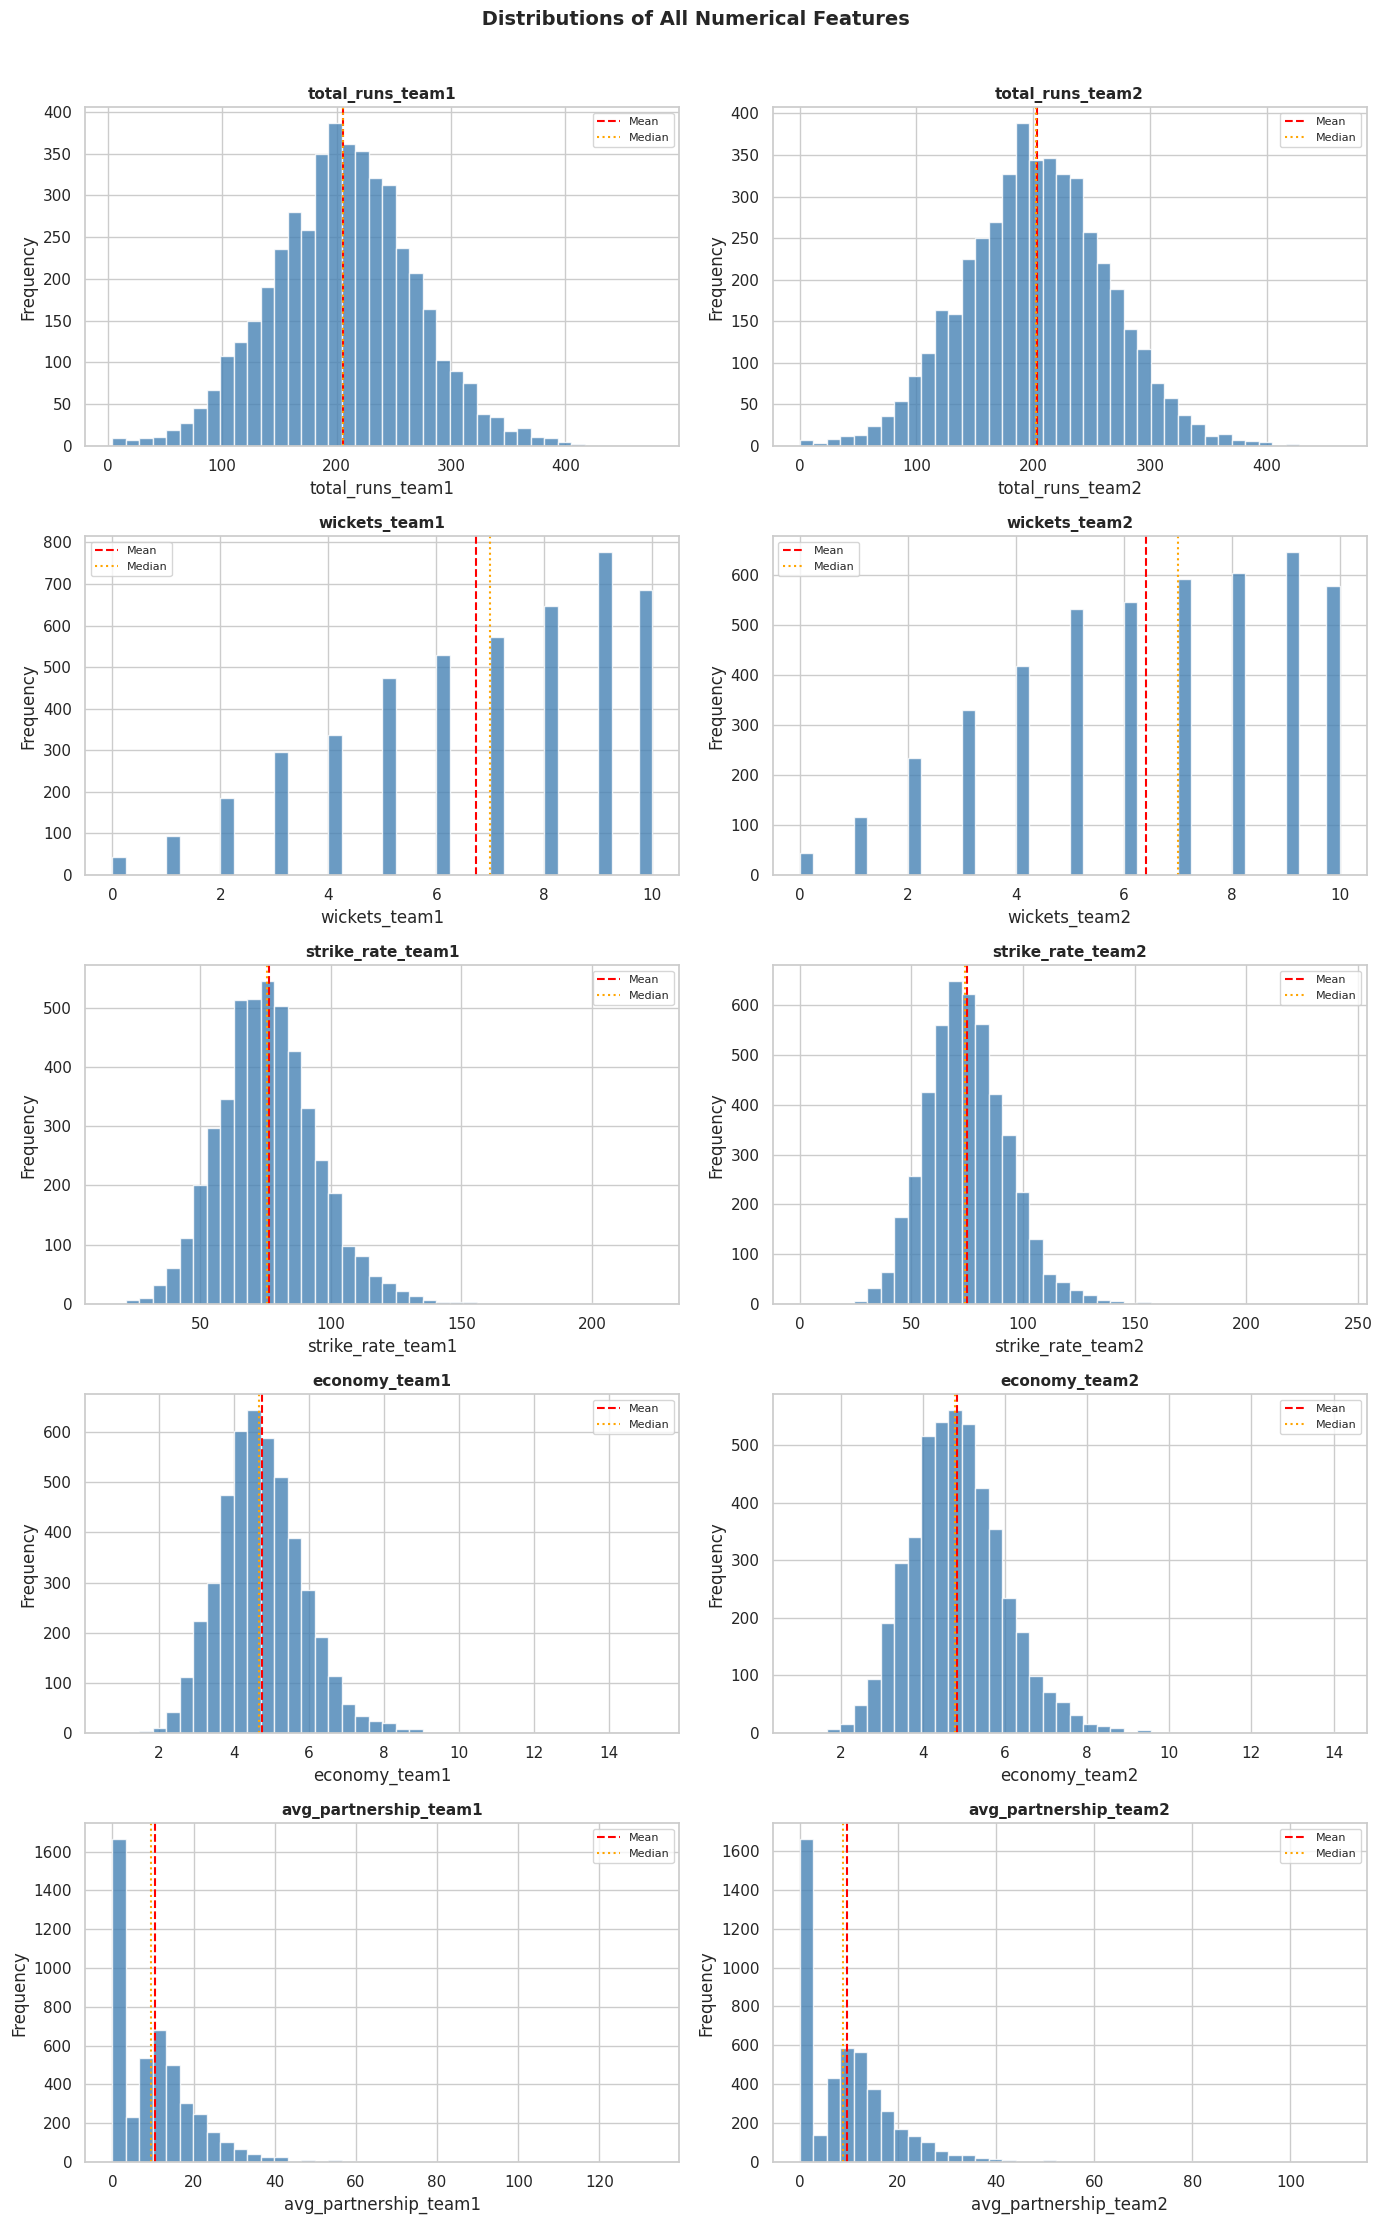

In [ ]:
# Distributions of All Numerical Features
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
axes = axes.flatten()

for i, col in enumerate(num_features):
    axes[i].hist(df[col], bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label='Mean')
    axes[i].axvline(df[col].median(), color='orange', linestyle=':',  linewidth=1.5, label='Median')
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)

plt.suptitle(' Distributions of All Numerical Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


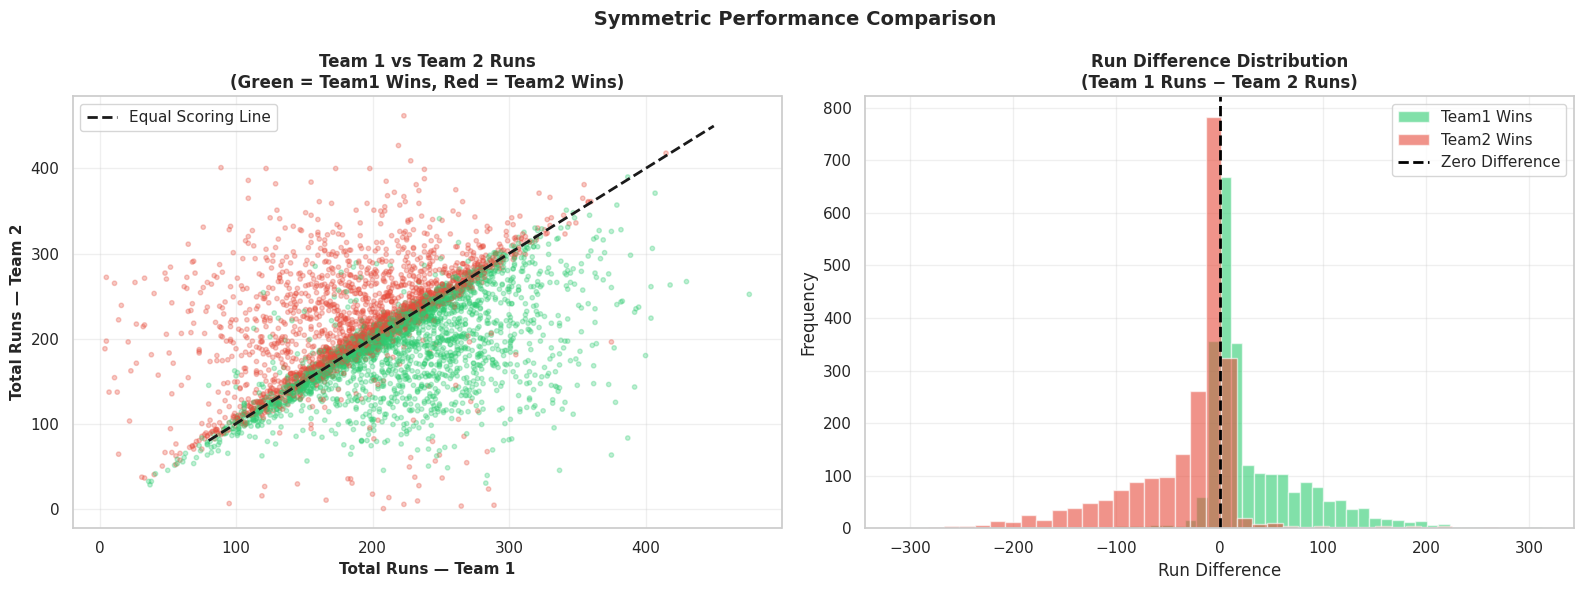

Team1 Wins: run_diff mean = 33.9, median = 12.0
Team2 Wins: run_diff mean = -31.7, median = -11.0


In [ ]:
#Symmetric Team Performance Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter: Team1 Runs vs Team2 Runs coloured by outcome
ax = axes[0]
colors_sc = ['#e74c3c' if x == 0 else '#2ecc71' for x in df['match_outcome']]
ax.scatter(df['total_runs_team1'], df['total_runs_team2'], c=colors_sc, alpha=0.3, s=10)
ax.plot([80, 450], [80, 450], 'k--', linewidth=2, label='Equal Scoring Line')
ax.set_xlabel('Total Runs — Team 1', fontsize=11, fontweight='bold')
ax.set_ylabel('Total Runs — Team 2', fontsize=11, fontweight='bold')
ax.set_title('Team 1 vs Team 2 Runs\n(Green = Team1 Wins, Red = Team2 Wins)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Run difference distribution by outcome
ax = axes[1]
for outcome, label, color in [(1,'Team1 Wins','#2ecc71'), (0,'Team2 Wins','#e74c3c')]:
    subset = df[df['match_outcome'] == outcome]['run_diff']
    ax.hist(subset, bins=40, alpha=0.6, label=label, color=color, edgecolor='white')
ax.axvline(0, color='black', linestyle='--', linewidth=2, label='Zero Difference')
ax.set_title('Run Difference Distribution\n(Team 1 Runs − Team 2 Runs)', fontsize=12, fontweight='bold')
ax.set_xlabel('Run Difference')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(' Symmetric Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary statistics for run difference
for outcome, label in [(1,'Team1 Wins'), (0,'Team2 Wins')]:
    rd = df[df['match_outcome']==outcome]['run_diff']
    print(f"{label}: run_diff mean = {rd.mean():.1f}, median = {rd.median():.1f}")


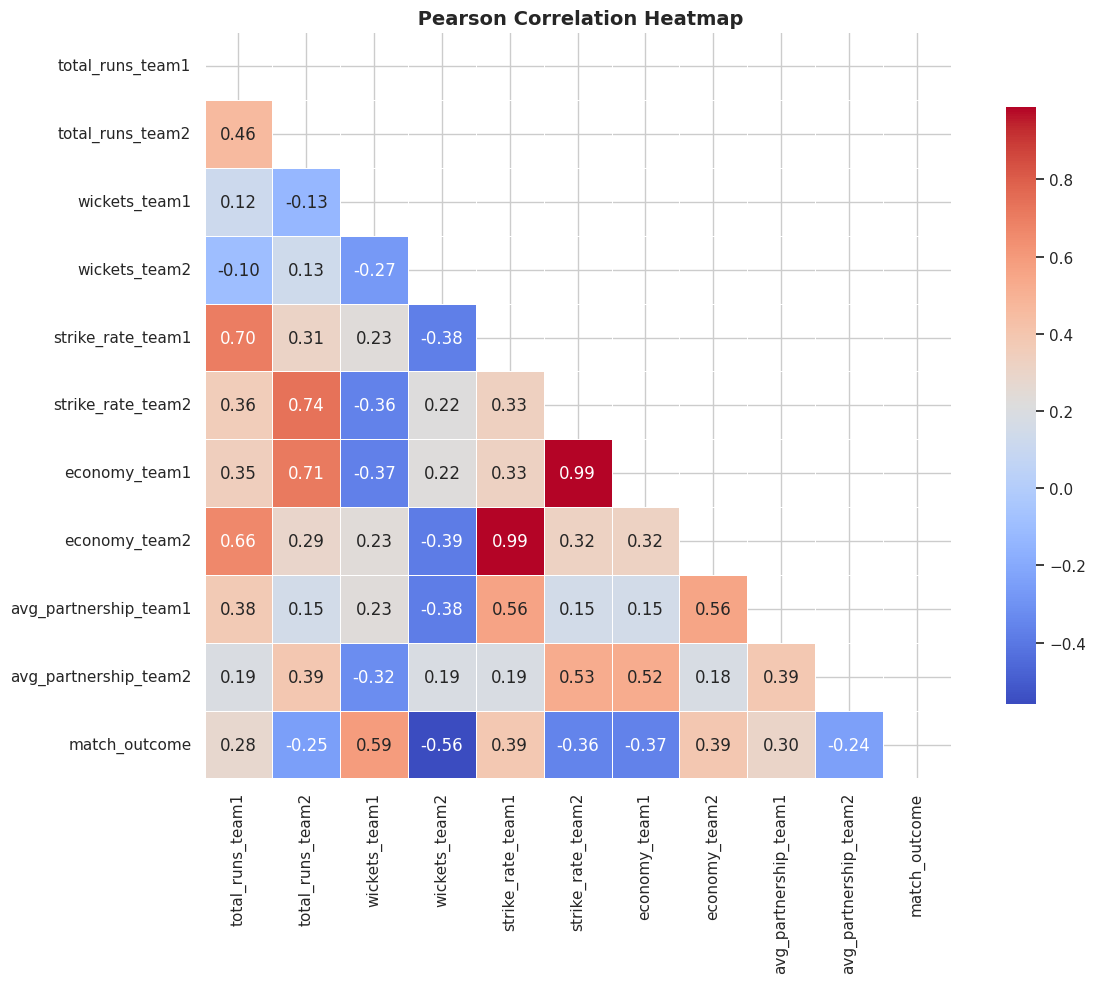

In [ ]:
#Correlation Heatmap
plt.figure(figsize=(13, 10))
corr_matrix = df[num_features + ['match_outcome']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8})
plt.title(' Pearson Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


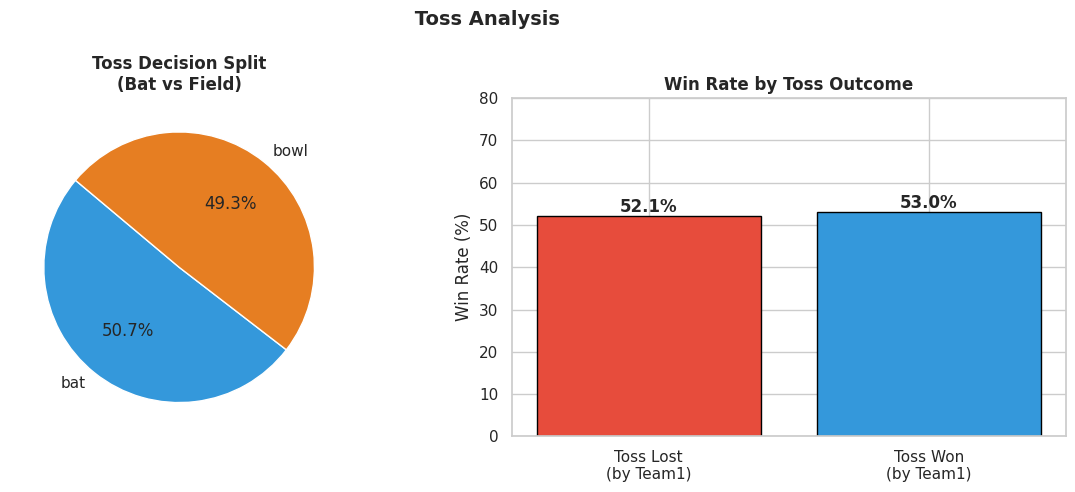

In [ ]:
#Toss Decision Analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

choice_counts = df['toss_winner_choice'].str.lower().str.strip().value_counts()
axes[0].pie(choice_counts.values, labels=choice_counts.index,
            autopct='%1.1f%%', startangle=140,
            colors=['#3498db','#e67e22'])
axes[0].set_title('Toss Decision Split\n(Bat vs Field)', fontsize=12, fontweight='bold')

toss_wr = df.groupby('toss_won_by_team1')['match_outcome'].mean()
bars = axes[1].bar(['Toss Lost\n(by Team1)', 'Toss Won\n(by Team1)'],
                   toss_wr[[0,1]].values * 100,
                   color=['#e74c3c','#3498db'], edgecolor='black')
axes[1].set_title('Win Rate by Toss Outcome', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Win Rate (%)')
axes[1].set_ylim(0, 80)
for bar, v in zip(bars, toss_wr[[0,1]].values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v*100 + 1,
                 f'{v*100:.1f}%', ha='center', fontweight='bold')

plt.suptitle(' Toss Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


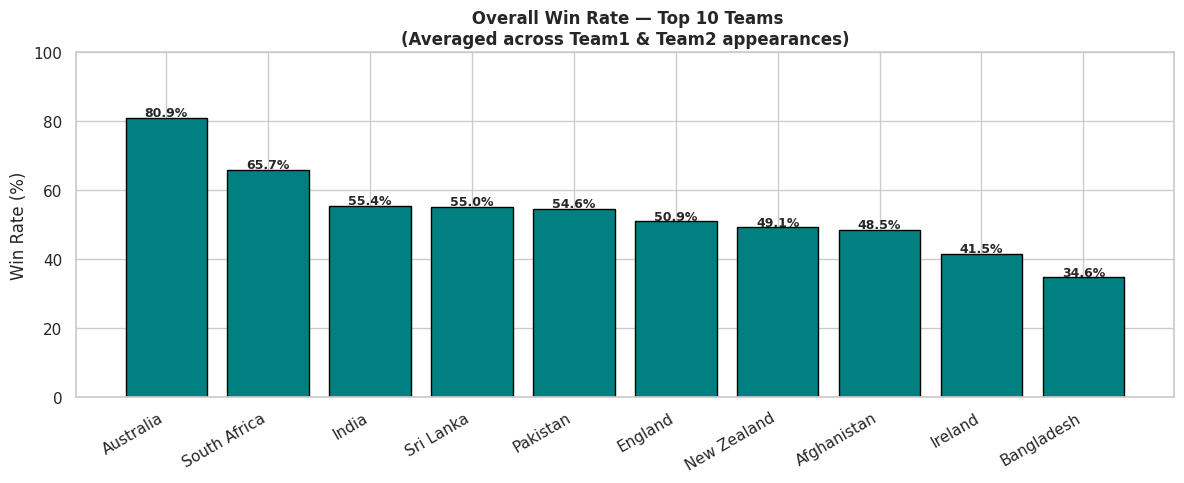

In [ ]:
#Win Rate by Team (Top 10 Teams)
top_teams = df['team1'].value_counts().head(10).index.tolist()

# Symmetric: compute win rate from BOTH team1 and team2 perspectives
win_as_t1 = (df[df['team1'].isin(top_teams)]
             .groupby('team1')['match_outcome'].mean())

# Win rate when the team appears as team2 (outcome=0 means team2 wins)
win_as_t2 = (df[df['team2'].isin(top_teams)]
             .groupby('team2')
             .apply(lambda x: (x['match_outcome'] == 0).mean()))

# Combine: average win rate regardless of team1/team2 designation
all_teams_wr = {}
for team in top_teams:
    rates = []
    if team in win_as_t1.index: rates.append(win_as_t1[team])
    if team in win_as_t2.index: rates.append(win_as_t2[team])
    all_teams_wr[team] = np.mean(rates) if rates else np.nan

wr_series = pd.Series(all_teams_wr).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(wr_series.index, wr_series.values * 100,
              color='teal', edgecolor='black')
for bar, val in zip(bars, wr_series.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val*100:.1f}%', ha='center', fontsize=9, fontweight='bold')
ax.set_title(' Overall Win Rate — Top 10 Teams\n(Averaged across Team1 & Team2 appearances)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Win Rate (%)')
ax.set_ylim(0, 100)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


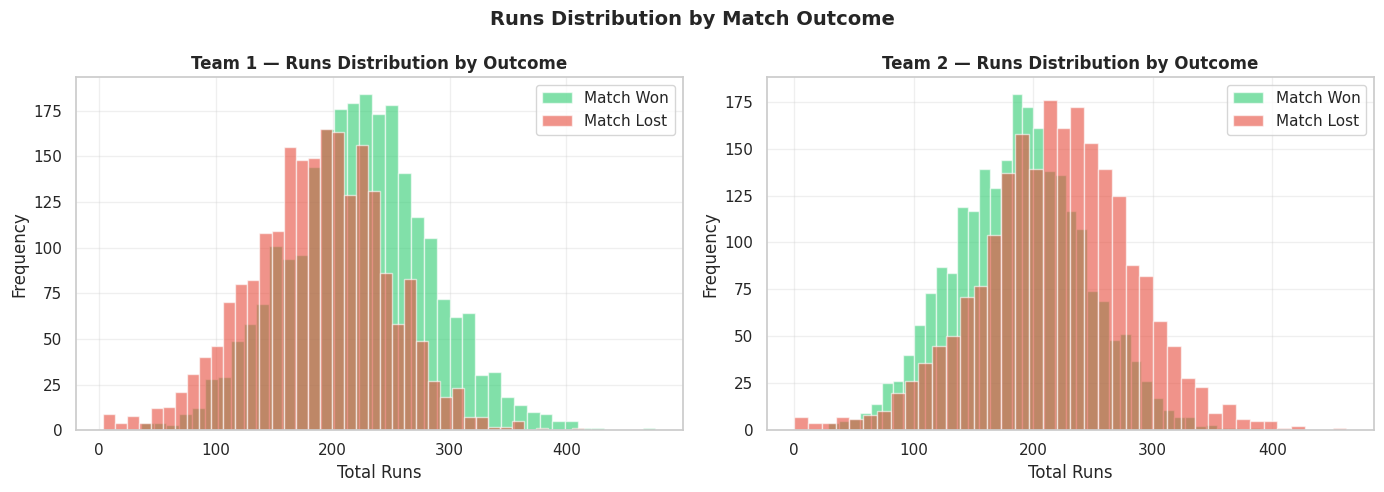

Team1 — Mean runs when winning: 222.1 | when losing: 187.2 | diff: 34.9
Team2 — Mean runs when winning: 188.3 | when losing: 218.9 | diff: 30.6


In [ ]:
#Exploratory Data Analysis (EDA)

#Runs Analysis by Outcome
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, team in zip(axes, ['total_runs_team1','total_runs_team2'], ['Team 1','Team 2']):
    for outcome, label, color in [(1,'Match Won','#2ecc71'),(0,'Match Lost','#e74c3c')]:
        subset = df[df['match_outcome'] == outcome][col]
        ax.hist(subset, bins=40, alpha=0.6, label=label, color=color, edgecolor='white')
    ax.set_title(f'{team} — Runs Distribution by Outcome', fontsize=12, fontweight='bold')
    ax.set_xlabel('Total Runs')
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Runs Distribution by Match Outcome', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary statistics
for team, col in [('Team1','total_runs_team1'),('Team2','total_runs_team2')]:
    w = df[df['match_outcome']==1][col].mean()
    l = df[df['match_outcome']==0][col].mean()
    print(f"{team} — Mean runs when winning: {w:.1f} | when losing: {l:.1f} | diff: {abs(w-l):.1f}")


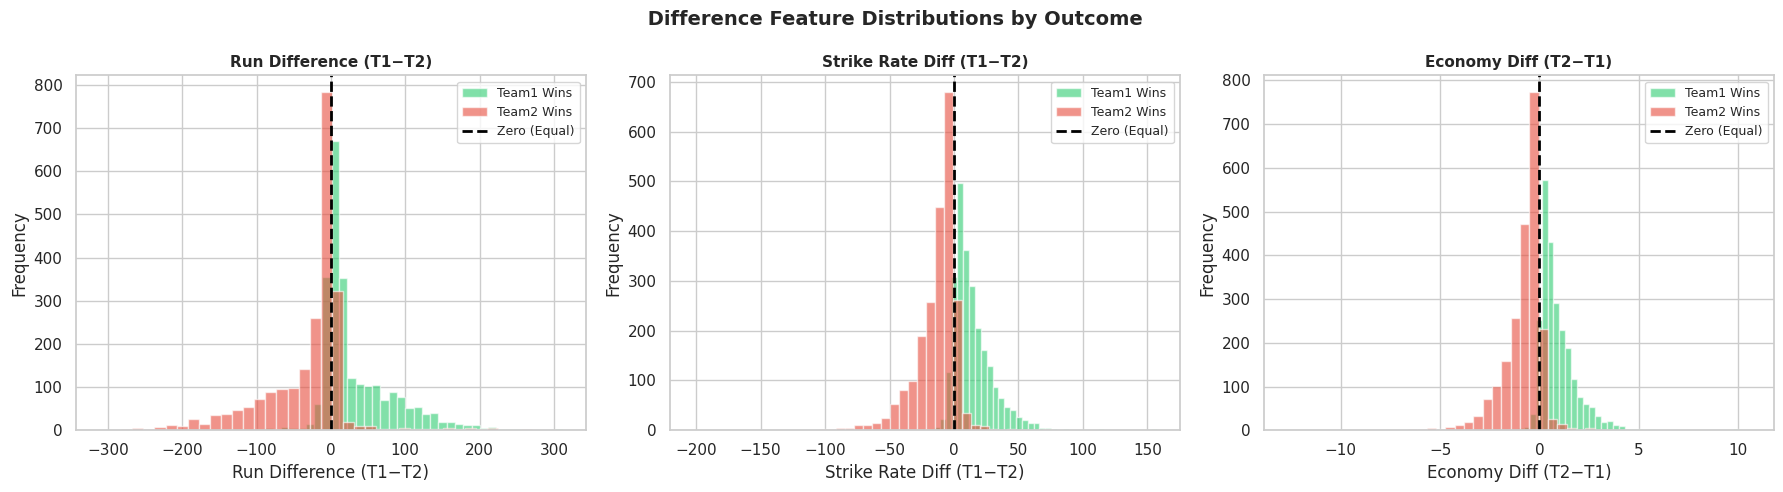

DIFFERENCE FEATURES — MEAN BY OUTCOME
run_diff                   Win: +33.86  Loss: -31.65  Gap:65.52
wicket_diff                Win:  +3.12  Loss:  -2.77  Gap:5.89
strike_rate_diff           Win: +14.54  Loss: -13.18  Gap:27.72
economy_diff               Win:  +0.92  Loss:  -0.81  Gap:1.72
partnership_diff           Win:  +6.56  Loss:  -5.58  Gap:12.14


In [ ]:
#Difference Features Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feat, title in zip(axes,
    ['run_diff','strike_rate_diff','economy_diff'],
    ['Run Difference (T1−T2)','Strike Rate Diff (T1−T2)','Economy Diff (T2−T1)']):
    for outcome, label, color in [(1,'Team1 Wins','#2ecc71'),(0,'Team2 Wins','#e74c3c')]:
        subset = df[df['match_outcome'] == outcome][feat]
        ax.hist(subset, bins=40, alpha=0.6, label=label, color=color, edgecolor='white')
    ax.axvline(0, color='black', linestyle='--', linewidth=2, label='Zero (Equal)')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(title)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)

plt.suptitle(' Difference Feature Distributions by Outcome', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 65)
print("DIFFERENCE FEATURES — MEAN BY OUTCOME")
print("=" * 65)
for feat in diff_features:
    m1 = df[df['match_outcome']==1][feat].mean()
    m0 = df[df['match_outcome']==0][feat].mean()
    print(f"{feat:<25s}  Win:{m1:+7.2f}  Loss:{m0:+7.2f}  Gap:{abs(m1-m0):.2f}")


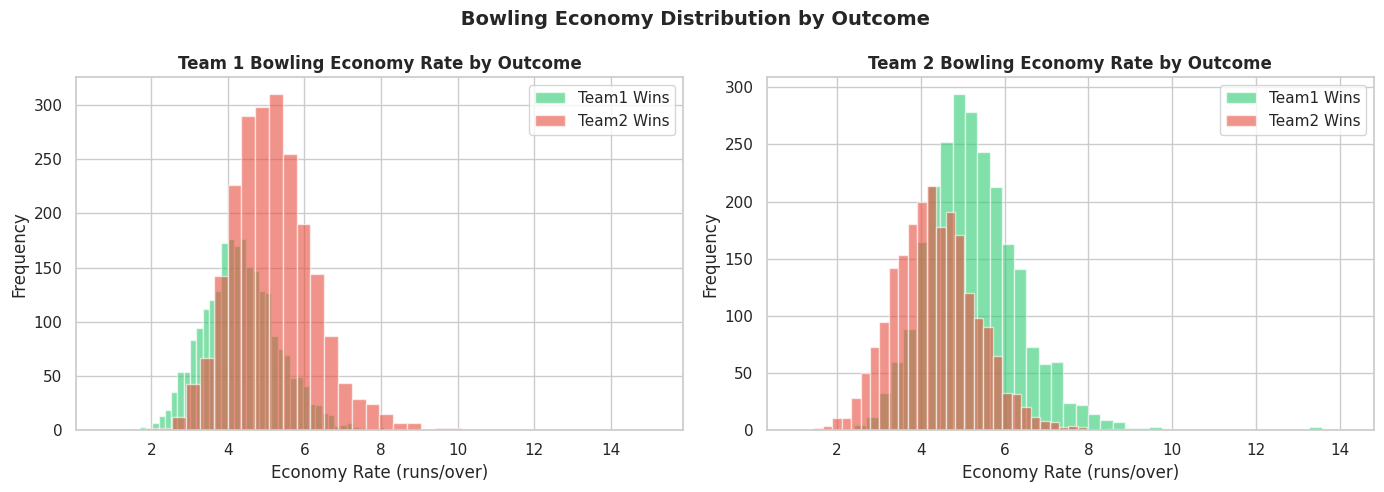

Team 1 Economy — when winning: 4.351 | when losing: 5.161
Team 2 Economy — when winning: 5.266 | when losing: 4.356


In [ ]:
#Bowling Economy Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, team in zip(axes, ['economy_team1','economy_team2'], ['Team 1 Bowling','Team 2 Bowling']):
    win_data  = df[df['match_outcome']==1][col]
    loss_data = df[df['match_outcome']==0][col]
    ax.hist(win_data,  bins=40, alpha=0.6, color='#2ecc71', label='Team1 Wins', edgecolor='white')
    ax.hist(loss_data, bins=40, alpha=0.6, color='#e74c3c', label='Team2 Wins', edgecolor='white')
    ax.set_title(f'{team} Economy Rate by Outcome', fontsize=12, fontweight='bold')
    ax.set_xlabel('Economy Rate (runs/over)')
    ax.set_ylabel('Frequency')
    ax.legend()

plt.suptitle(' Bowling Economy Distribution by Outcome', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Economy means
print("Team 1 Economy — when winning:", df[df['match_outcome']==1]['economy_team1'].mean().round(3),
      "| when losing:", df[df['match_outcome']==0]['economy_team1'].mean().round(3))
print("Team 2 Economy — when winning:", df[df['match_outcome']==1]['economy_team2'].mean().round(3),
      "| when losing:", df[df['match_outcome']==0]['economy_team2'].mean().round(3))


In [ ]:
# Hypothesis Formulation and Testing
alpha = 0.05
print(f"Significance level (α) = {alpha}")


Significance level (α) = 0.05


## Hypothesis 1: Does Scoring More Runs Than the Opponent Lead to Winning?

**H₀:** The run gap between the two teams (Team 1 runs − Team 2 runs) is the same whether Team 1 wins or loses — i.e., scoring more runs than the opponent does **not** affect the match result.  
**H₁:** The run gap is significantly larger in matches that Team 1 wins — i.e., the team that outscores its opponent wins more often.  
**Test:** Independent samples t-test (Welch's, two-tailed) on `run_diff` across win/loss groups.


In [ ]:
wins  = df[df['match_outcome'] == 1]['run_diff']
losses= df[df['match_outcome'] == 0]['run_diff']

t1, p1 = ttest_ind(wins, losses, equal_var=False)

print("=" * 60)
print("H1 — t-Test: Run Differential vs Match Outcome")
print("=" * 60)
print(f"Win   group — Mean: {wins.mean():.2f},  Std: {wins.std():.2f},  n: {len(wins)}")
print(f"Loss  group — Mean: {losses.mean():.2f},  Std: {losses.std():.2f},  n: {len(losses)}")
print(f"\nt-statistic : {t1:.4f}")
print(f"p-value     : {p1:.2e}")
print(f"Decision    : {'REJECT H₀' if p1 < alpha else 'FAIL TO REJECT H₀'} at α = {alpha}")


H1 — t-Test: Run Differential vs Match Outcome
Win   group — Mean: 33.86,  Std: 51.24,  n: 2442
Loss  group — Mean: -31.65,  Std: 59.57,  n: 2202

t-statistic : 39.9705
p-value     : 5.41e-298
Decision    : REJECT H₀ at α = 0.05


## Hypothesis 2: Does Batting More Aggressively Than the Opponent Lead to Winning?

**H₀:** The strike rate gap between the two teams (Team 1 SR − Team 2 SR) is the same whether Team 1 wins or loses — i.e., batting at a faster pace than the opponent does **not** affect the match result.  
**H₁:** The strike rate gap is significantly larger in matches that Team 1 wins — i.e., the team that bats more aggressively wins more often.  
**Test:** Independent samples t-test (Welch's, two-tailed) on `strike_rate_diff` across win/loss groups.


In [ ]:
sr_wins  = df[df['match_outcome'] == 1]['strike_rate_diff']
sr_losses= df[df['match_outcome'] == 0]['strike_rate_diff']

t2, p2 = ttest_ind(sr_wins, sr_losses, equal_var=False)

print("=" * 60)
print("H2 — t-Test: Strike Rate Differential vs Match Outcome")
print("=" * 60)
print(f"Win   group — Mean: {sr_wins.mean():.3f}")
print(f"Loss  group — Mean: {sr_losses.mean():.3f}")
print(f"\nt-statistic : {t2:.4f}")
print(f"p-value     : {p2:.2e}")
print(f"Decision    : {'REJECT H₀' if p2 < alpha else 'FAIL TO REJECT H₀'} at α = {alpha}")


H2 — t-Test: Strike Rate Differential vs Match Outcome
Win   group — Mean: 14.539
Loss  group — Mean: -13.179

t-statistic : 57.1119
p-value     : 0.00e+00
Decision    : REJECT H₀ at α = 0.05


## Hypothesis 3: Toss Winner Choice and Match Outcome

**H₀:** Toss winner's decision (bat/field) is independent of match outcome.  
**H₁:** There is a statistically significant association between toss choice and match outcome.  
**Test:** Chi-Square Test of Independence

In [ ]:
ct = pd.crosstab(df['toss_choice_encoded'], df['match_outcome'])
chi2_h3, p_h3, dof_h3, expected_h3 = chi2_contingency(ct)

print("=" * 60)
print("H3 — Chi-Square: Toss Choice vs Match Outcome")
print("=" * 60)
print("Contingency Table:")
print(ct)
print(f"\nChi² Statistic     : {chi2_h3:.4f}")
print(f"Degrees of Freedom : {dof_h3}")
print(f"p-value            : {p_h3:.6f}")
print(f"Decision           : {'REJECT H₀' if p_h3 < alpha else 'FAIL TO REJECT H₀'} at α = {alpha}")


H3 — Chi-Square: Toss Choice vs Match Outcome
Contingency Table:
match_outcome           0     1
toss_choice_encoded            
0                    1078  1213
1                    1124  1229

Chi² Statistic     : 0.2103
Degrees of Freedom : 1
p-value            : 0.646558
Decision           : FAIL TO REJECT H₀ at α = 0.05


## Hypothesis 4: Economy Rate Consistency Across Top Teams

**H₀:** The mean bowling economy rate (in winning matches) is equal across the top 5 teams.  
**H₁:** At least one team's winning economy rate differs significantly.  
**Test:** One-Way ANOVA

In [ ]:
top5 = df['team1'].value_counts().head(5).index.tolist()

# Use symmetric metric: compute economy advantage (economy_diff) in winning matches
groups = [
    df[(df['team1'] == t) & (df['match_outcome'] == 1)]['economy_diff'].values
    for t in top5
]

f_stat, p_anova = f_oneway(*groups)

print("=" * 65)
print("H4 — ANOVA: Economy Advantage Across Top 5 Teams (Wins)")
print("=" * 65)
for t, g in zip(top5, groups):
    print(f"  {t:<25s}  mean econ_diff = {np.mean(g):.4f}  n = {len(g)}")
print(f"\nF-statistic : {f_stat:.4f}")
print(f"p-value     : {p_anova:.6f}")
print(f"Decision    : {'REJECT H₀' if p_anova < alpha else 'FAIL TO REJECT H₀'} at α = {alpha}")


H4 — ANOVA: Economy Advantage Across Top 5 Teams (Wins)
  Australia                  mean econ_diff = 0.8987  n = 604
  India                      mean econ_diff = 0.9313  n = 405
  England                    mean econ_diff = 0.8550  n = 312
  Pakistan                   mean econ_diff = 0.8106  n = 246
  Bangladesh                 mean econ_diff = 0.9470  n = 148

F-statistic : 0.8982
p-value     : 0.464129
Decision    : FAIL TO REJECT H₀ at α = 0.05


## Hypothesis 5: Toss Outcome and Match Outcome

**H₀:** Whether Team 1 wins the toss is independent of whether Team 1 wins the match.  
**H₁:** There is a significant association between toss winner and match winner.  
**Test:** Chi-Square Test of Independence

In [ ]:
ct2 = pd.crosstab(df['toss_won_by_team1'], df['match_outcome'])
chi2_h5, p_h5, dof_h5, _ = chi2_contingency(ct2)

# Cramér's V for effect size
n = len(df)
cramers_v = np.sqrt(chi2_h5 / (n * (min(ct2.shape) - 1)))

print("=" * 60)
print("H5 — Chi-Square: Toss Win vs Match Win")
print("=" * 60)
print("Contingency Table:")
print(ct2)
print(f"\nChi² : {chi2_h5:.4f}  | dof : {dof_h5}  | p-value : {p_h5:.6f}")
print(f"Cramér's V (effect size) : {cramers_v:.4f}  {'(negligible)' if cramers_v < 0.1 else '(small)' if cramers_v < 0.3 else '(medium)'}")
print(f"Decision : {'REJECT H₀' if p_h5 < alpha else 'FAIL TO REJECT H₀'} at α = {alpha}")


H5 — Chi-Square: Toss Win vs Match Win
Contingency Table:
match_outcome         0     1
toss_won_by_team1            
0                  1100  1198
1                  1102  1244

Chi² : 0.3372  | dof : 1  | p-value : 0.561428
Cramér's V (effect size) : 0.0085  (negligible)
Decision : FAIL TO REJECT H₀ at α = 0.05



 ## Advanced Statistical Methods




## Pearson Correlation Analysis

In [ ]:
feat_cols = num_features + ['toss_won_by_team1', 'toss_choice_encoded']

print("Pearson Correlations with match_outcome :")
print("=" * 60)
corrs = df[feat_cols].corrwith(df['match_outcome']).sort_values(key=abs, ascending=False)
for feat, val in corrs.items():
    bar = '█' * int(abs(val) * 30)
    direction = '+' if val > 0 else '-'
    print(f"  {feat:<32s} {direction}{abs(val):.4f}  {bar}")


Pearson Correlations with match_outcome :
  wickets_team1                    +0.5919  █████████████████
  wickets_team2                    -0.5587  ████████████████
  economy_team2                    +0.3903  ███████████
  strike_rate_team1                +0.3853  ███████████
  economy_team1                    -0.3651  ██████████
  strike_rate_team2                -0.3572  ██████████
  avg_partnership_team1            +0.3025  █████████
  total_runs_team1                 +0.2799  ████████
  total_runs_team2                 -0.2496  ███████
  avg_partnership_team2            -0.2441  ███████
  toss_won_by_team1                +0.0090  
  toss_choice_encoded              -0.0072  


## Multiple Linear Regression



MULTIPLE LINEAR REGRESSION — Predicting total_runs_team1
R² Score : 0.4718
RMSE     : 45.21 runs

Coefficients:
  wickets_team1                  : -0.8488
  strike_rate_team1              : +5.3644
  economy_team2                  : -49.2728
  avg_partnership_team1          : +0.0087
  Intercept                      : +39.9090


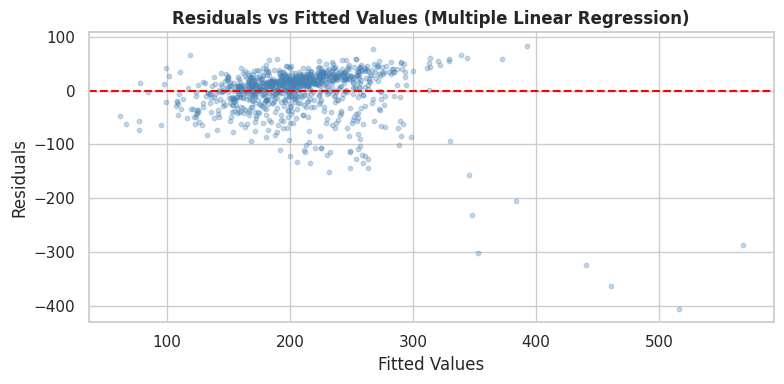

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

X_lr = df[['wickets_team1','strike_rate_team1','economy_team2','avg_partnership_team1']]
y_lr = df['total_runs_team1']

X_tr, X_te, y_tr, y_te = train_test_split(X_lr, y_lr, test_size=0.2, random_state=42)
lr = LinearRegression()
lr.fit(X_tr, y_tr)
y_pred_lr = lr.predict(X_te)

r2  = r2_score(y_te, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_te, y_pred_lr))

print("=" * 65)
print("MULTIPLE LINEAR REGRESSION — Predicting total_runs_team1")
print("=" * 65)
print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.2f} runs")
print("\nCoefficients:")
for name, coef in zip(X_lr.columns, lr.coef_):
    print(f"  {name:<30s} : {coef:+.4f}")
print(f"  Intercept                      : {lr.intercept_:+.4f}")

# Residual plot
residuals = y_te.values - y_pred_lr
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_pred_lr, residuals, alpha=0.3, color='steelblue', s=10)
ax.axhline(0, color='red', linestyle='--')
ax.set_title('Residuals vs Fitted Values (Multiple Linear Regression)', fontsize=12, fontweight='bold')
ax.set_xlabel('Fitted Values')
ax.set_ylabel('Residuals')
plt.tight_layout()
plt.show()


##  Principal Component Analysis (PCA)

PCA — Explained Variance per Component
  PC 1 : 41.11%  cumulative :  41.11%
  PC 2 : 26.45%  cumulative :  67.55%
  PC 3 :  9.57%  cumulative :  77.13%
  PC 4 :  7.23%  cumulative :  84.36%
  PC 5 :  6.16%  cumulative :  90.51%
  PC 6 :  4.20%  cumulative :  94.71%
  PC 7 :  2.92%  cumulative :  97.63%
  PC 8 :  2.13%  cumulative :  99.77%
  PC 9 :  0.15%  cumulative :  99.92%
  PC10 :  0.08%  cumulative : 100.00%


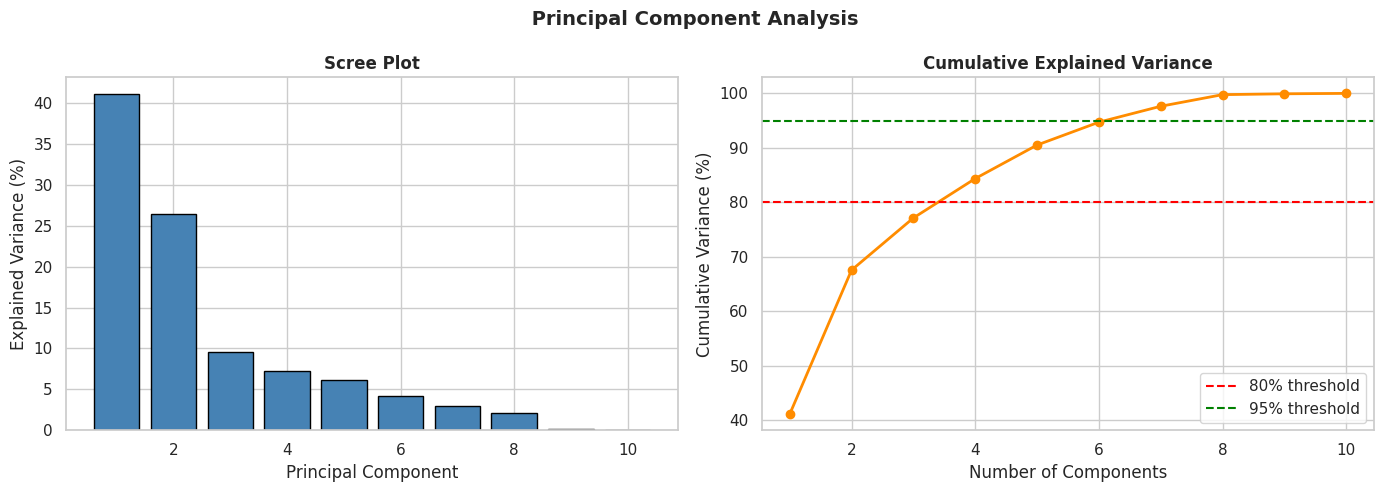


Components for 80% variance: 4
Components for 95% variance: 7


In [ ]:
X_pca_data = df_scaled[num_features]  # standardised

pca_full = PCA(n_components=None, random_state=42)
pca_full.fit(X_pca_data)
explained   = pca_full.explained_variance_ratio_
cumulative  = np.cumsum(explained)

print("=" * 55)
print("PCA — Explained Variance per Component")
print("=" * 55)
for i, (e, c) in enumerate(zip(explained, cumulative)):
    print(f"  PC{i+1:>2d} : {e*100:5.2f}%  cumulative : {c*100:6.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(explained)+1), explained*100, color='steelblue', edgecolor='black')
axes[0].set_title('Scree Plot', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')

axes[1].plot(range(1, len(cumulative)+1), cumulative*100, marker='o', color='darkorange', linewidth=2)
axes[1].axhline(80, color='red',   linestyle='--', label='80% threshold')
axes[1].axhline(95, color='green', linestyle='--', label='95% threshold')
axes[1].set_title('Cumulative Explained Variance', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.suptitle(' Principal Component Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

n80 = np.argmax(cumulative >= 0.80) + 1
n95 = np.argmax(cumulative >= 0.95) + 1
print(f"\nComponents for 80% variance: {n80}")
print(f"Components for 95% variance: {n95}")


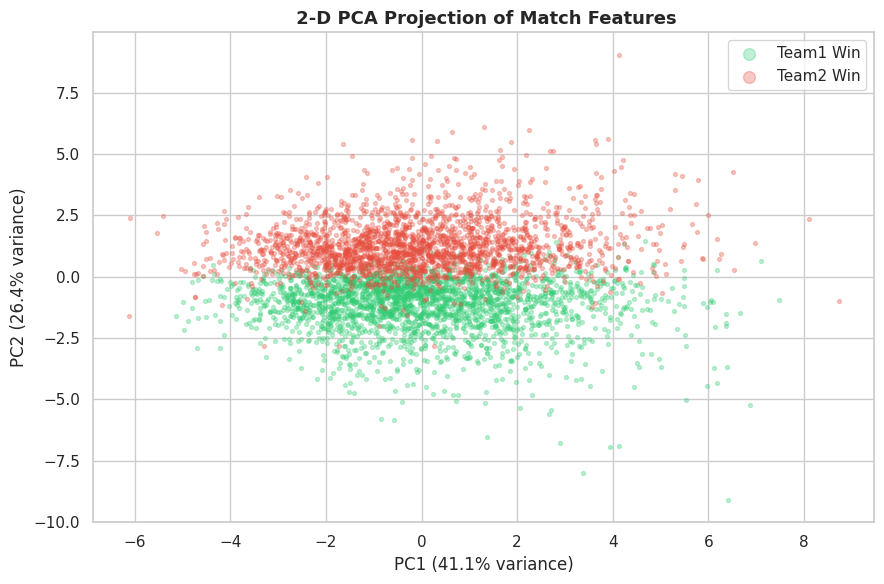

In [ ]:
# 2-D PCA scatter plot
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_pca_data)

y_target = df['match_outcome'].values
fig, ax = plt.subplots(figsize=(9, 6))
for outcome, label, color in [(1,'Team1 Win','#2ecc71'), (0,'Team2 Win','#e74c3c')]:
    mask_pca = (y_target == outcome)
    ax.scatter(X_pca2[mask_pca, 0], X_pca2[mask_pca, 1],
               c=color, alpha=0.3, s=8, label=label)
ax.set_title(' 2-D PCA Projection of Match Features', fontsize=13, fontweight='bold')
ax.set_xlabel(f'PC1 ({explained[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({explained[1]*100:.1f}% variance)')
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()


##  K-Means Clustering

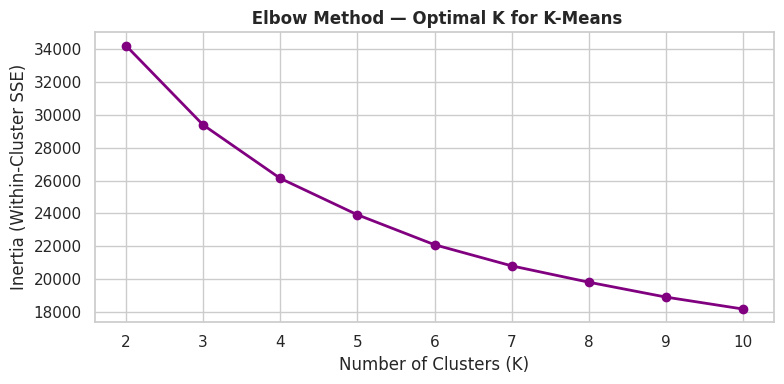

Cluster sizes: {2: 2204, 1: 1260, 0: 1180}

Win rate (Team1) per cluster:
cluster
0    0.0441
1    0.8849
2    0.5785
Name: match_outcome, dtype: float64

Cluster mean total runs (Team1/Team2):
         total_runs_team1  total_runs_team2
cluster                                    
0                   203.1             245.1
1                   260.9             224.1
2                   175.3             167.9


In [ ]:
# Elbow method
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_pca_data)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), inertias, marker='o', color='purple', linewidth=2)
ax.set_title(' Elbow Method — Optimal K for K-Means', fontsize=12, fontweight='bold')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Inertia (Within-Cluster SSE)')
plt.tight_layout()
plt.show()

# Fit with K=3
km3 = KMeans(n_clusters=3, n_init=10, random_state=42)
df['cluster'] = km3.fit_predict(X_pca_data)

print("Cluster sizes:", df['cluster'].value_counts().to_dict())
print("\nWin rate (Team1) per cluster:")
print(df.groupby('cluster')['match_outcome'].mean().round(4))
print("\nCluster mean total runs (Team1/Team2):")
print(df.groupby('cluster')[['total_runs_team1','total_runs_team2']].mean().round(1))


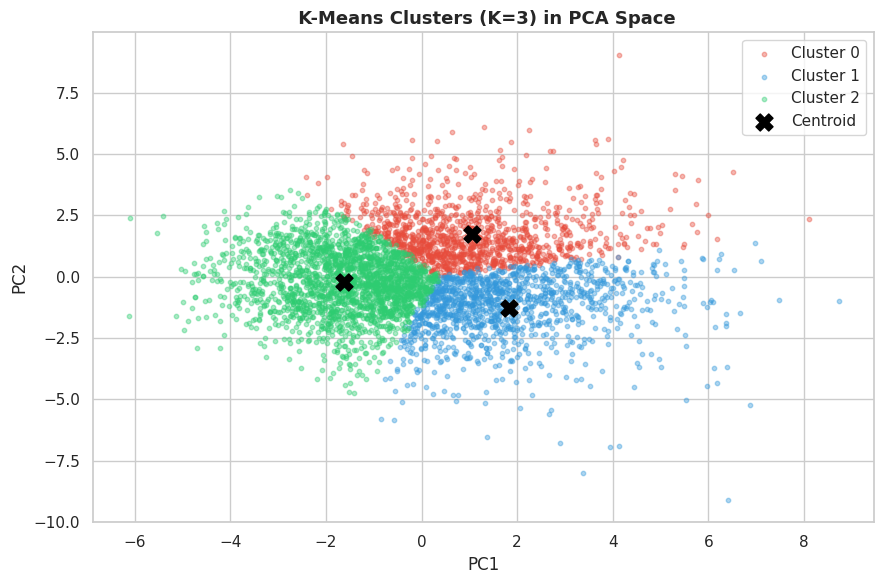

In [ ]:
# Cluster visualisation
fig, ax = plt.subplots(figsize=(9, 6))
palette = {0:'#e74c3c', 1:'#3498db', 2:'#2ecc71'}
for c in range(3):
    mask_c = (df['cluster'].values == c)
    ax.scatter(X_pca2[mask_c, 0], X_pca2[mask_c, 1],
               c=palette[c], alpha=0.4, s=10, label=f'Cluster {c}')
centroids_2d = pca2.transform(km3.cluster_centers_)
ax.scatter(centroids_2d[:,0], centroids_2d[:,1],
           c='black', s=150, marker='X', zorder=5, label='Centroid')
ax.set_title(' K-Means Clusters (K=3) in PCA Space', fontsize=13, fontweight='bold')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend()
plt.tight_layout()
plt.show()



#  Classification Model Building




In [ ]:
# ── Train-test split ─────────────────────────────────────
feat_cols = num_features + ['toss_won_by_team1', 'toss_choice_encoded']
X = df[feat_cols]
y = df['match_outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training samples : {X_train.shape[0]}")
print(f"Test samples     : {X_test.shape[0]}")
print(f"Features used    : {X_train.shape[1]}")
print(f"\nTarget distribution (train): {dict(y_train.value_counts())}")
print(f"Target distribution (test) : {dict(y_test.value_counts())}")


Training samples : 3715
Test samples     : 929
Features used    : 12

Target distribution (train): {1: np.int64(1953), 0: np.int64(1762)}
Target distribution (test) : {1: np.int64(489), 0: np.int64(440)}


In [ ]:
# ── Model definitions ────────────────────────────────────
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=150, max_depth=12,
                                                    random_state=42, n_jobs=-1),

}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    try:
        y_prob = model.predict_proba(X_test)[:, 1]
    except AttributeError:
        y_prob = model.decision_function(X_test)
    auc = roc_auc_score(y_test, y_prob)
    results[name] = {'model': model, 'y_pred': y_pred, 'y_prob': y_prob,
                     'accuracy': acc, 'precision': prec,
                     'recall': rec, 'f1': f1, 'auc': auc}
    print(f"{'='*50}\nMODEL: {name}\n{'='*50}")
    print(f"  Accuracy  : {acc:.4f}")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1 Score  : {f1:.4f}")
    print(f"  ROC-AUC   : {auc:.4f}\n")


MODEL: Logistic Regression
  Accuracy  : 0.9268
  Precision : 0.9218
  Recall    : 0.9407
  F1 Score  : 0.9312
  ROC-AUC   : 0.9782

MODEL: Decision Tree
  Accuracy  : 0.8999
  Precision : 0.8852
  Recall    : 0.9305
  F1 Score  : 0.9073
  ROC-AUC   : 0.9280

MODEL: Random Forest
  Accuracy  : 0.9333
  Precision : 0.9245
  Recall    : 0.9509
  F1 Score  : 0.9375
  ROC-AUC   : 0.9820



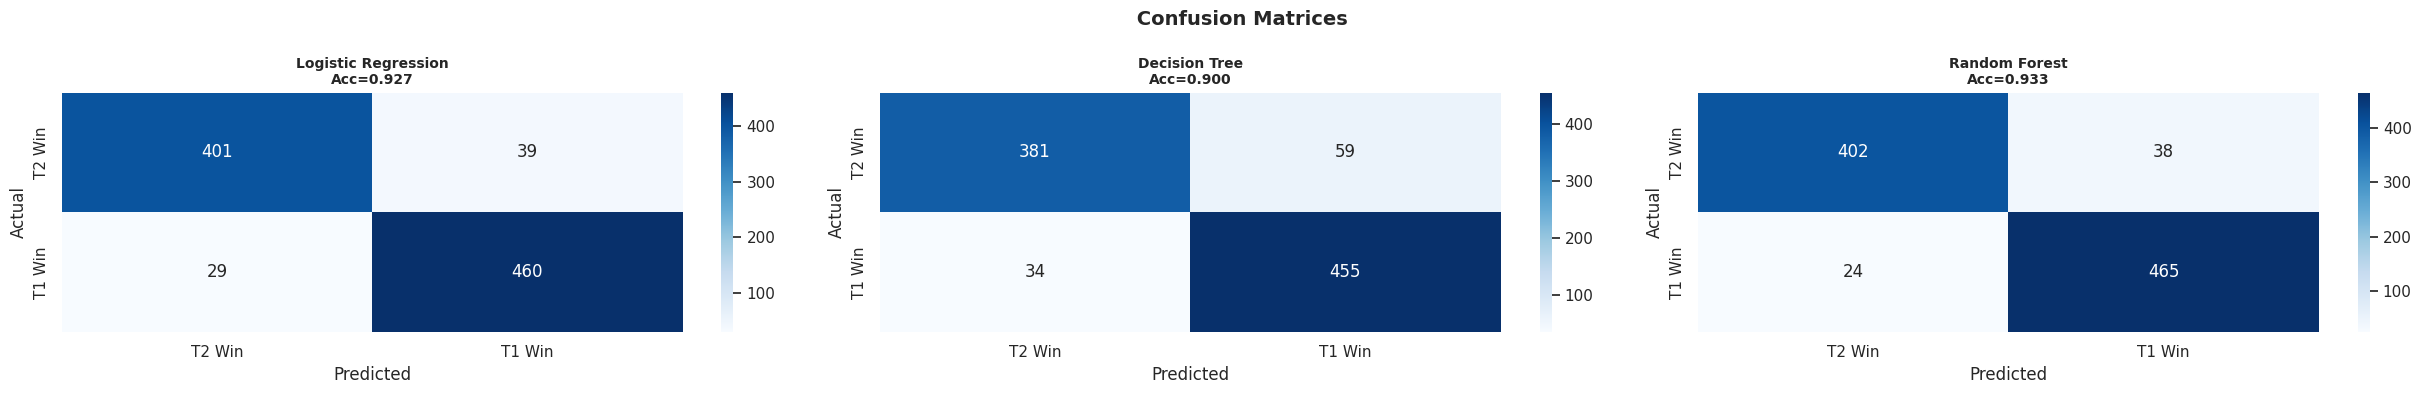

In [ ]:
# ── Confusion matrices ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(25, 4))

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['T2 Win', 'T1 Win'],
                yticklabels=['T2 Win', 'T1 Win'])
    ax.set_title(f'{name}\nAcc={res["accuracy"]:.3f}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.suptitle(' Confusion Matrices ', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


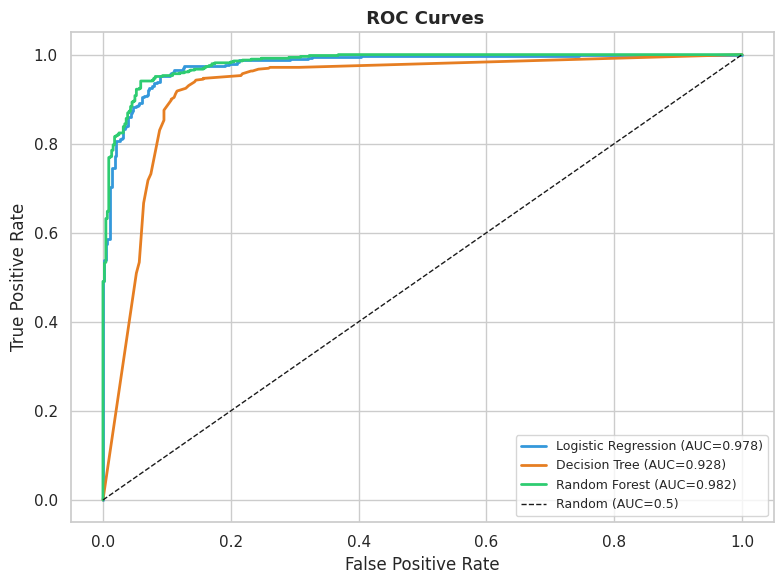

In [ ]:
# ── ROC Curves ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = ['#3498db','#e67e22','#2ecc71','#9b59b6','#e74c3c']

for (name, res), color in zip(results.items(), colors_roc):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f'{name} (AUC={res["auc"]:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.5)')
ax.set_title(' ROC Curves', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


MODEL COMPARISON TABLE
                     Accuracy  Precision  Recall      F1     AUC
Logistic Regression    0.9268     0.9218  0.9407  0.9312  0.9782
Decision Tree          0.8999     0.8852  0.9305  0.9073  0.9280
Random Forest          0.9333     0.9245  0.9509  0.9375  0.9820


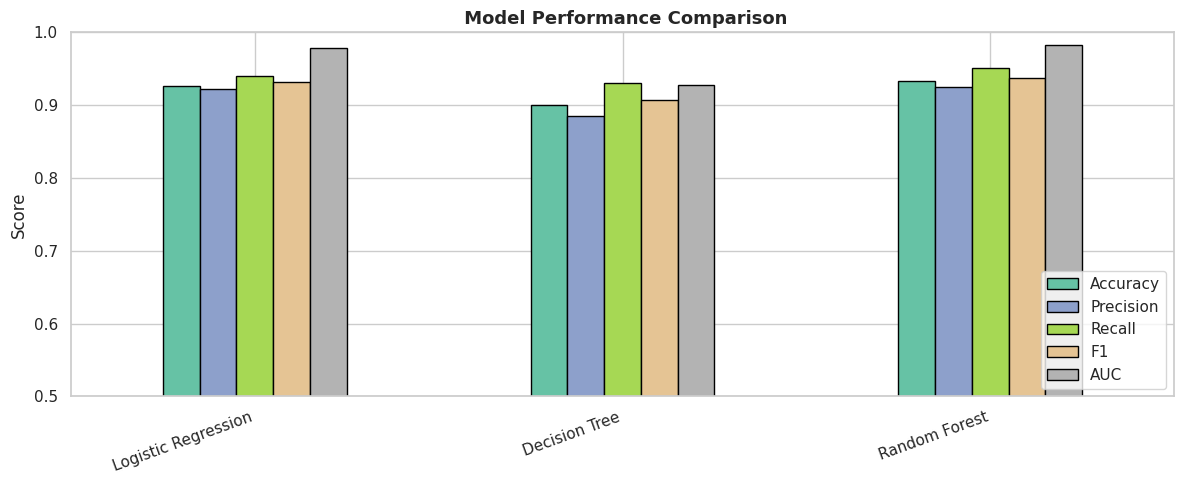

In [ ]:
# ── Model comparison table + bar chart ───────────────────
summary = pd.DataFrame(
    {name: {'Accuracy': res['accuracy'], 'Precision': res['precision'],
            'Recall': res['recall'], 'F1': res['f1'], 'AUC': res['auc']}
     for name, res in results.items()}
).T.round(4)

print("=" * 65)
print("MODEL COMPARISON TABLE")
print("=" * 65)
print(summary.to_string())

fig, ax = plt.subplots(figsize=(12, 5))
summary[['Accuracy','Precision','Recall','F1','AUC']].plot(
    kind='bar', ax=ax, colormap='Set2', edgecolor='black')
ax.set_title(' Model Performance Comparison', fontsize=13, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.legend(loc='lower right')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


In [ ]:
# ── Full classification reports ──────────────────────────
for name, res in results.items():
    print(f"{'='*55}")
    print(f"Classification Report: {name}")
    print(f"{'='*55}")
    print(classification_report(y_test, res['y_pred'],
                                target_names=['Team2 Wins (0)', 'Team1 Wins (1)']))


Classification Report: Logistic Regression
                precision    recall  f1-score   support

Team2 Wins (0)       0.93      0.91      0.92       440
Team1 Wins (1)       0.92      0.94      0.93       489

      accuracy                           0.93       929
     macro avg       0.93      0.93      0.93       929
  weighted avg       0.93      0.93      0.93       929

Classification Report: Decision Tree
                precision    recall  f1-score   support

Team2 Wins (0)       0.92      0.87      0.89       440
Team1 Wins (1)       0.89      0.93      0.91       489

      accuracy                           0.90       929
     macro avg       0.90      0.90      0.90       929
  weighted avg       0.90      0.90      0.90       929

Classification Report: Random Forest
                precision    recall  f1-score   support

Team2 Wins (0)       0.94      0.91      0.93       440
Team1 Wins (1)       0.92      0.95      0.94       489

      accuracy                     


# Feature Importance Analysis




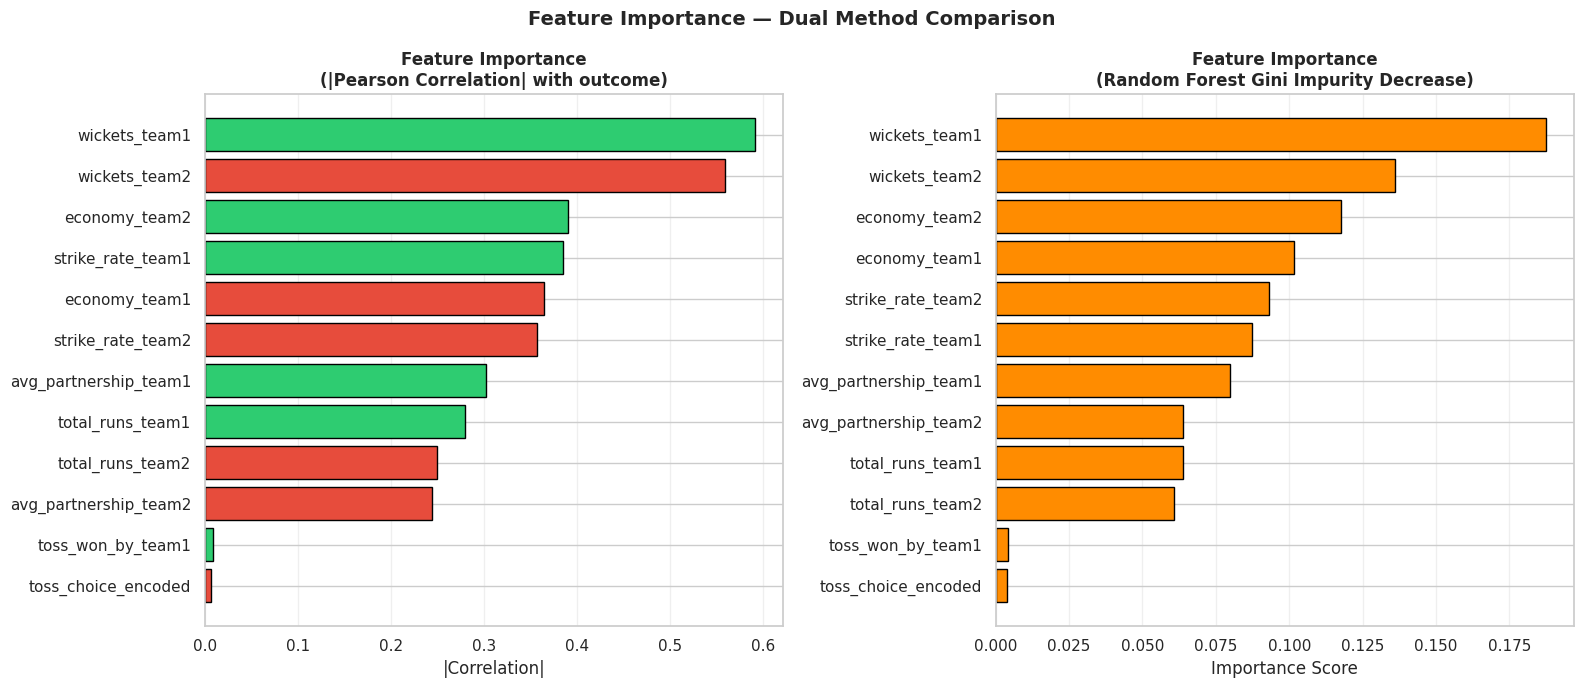

Top 5 features (Random Forest):
wickets_team1        0.1876
wickets_team2        0.1359
economy_team2        0.1178
economy_team1        0.1017
strike_rate_team2    0.0931
dtype: float64


In [ ]:
# ── Correlation-based importance ──────────────────────────
corr_imp = df[feat_cols].corrwith(df['match_outcome'])
corr_sign = corr_imp.copy()
corr_imp_abs = corr_imp.abs().sort_values(ascending=False)

# Random Forest importance
rf_best = results['Random Forest']['model']
fi = pd.Series(rf_best.feature_importances_, index=feat_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Correlation plot
colors_corr = ['#2ecc71' if corr_sign[f] > 0 else '#e74c3c' for f in corr_imp_abs.index]
axes[0].barh(corr_imp_abs.index, corr_imp_abs.values, color=colors_corr, edgecolor='black')
axes[0].set_title('Feature Importance\n(|Pearson Correlation| with outcome)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('|Correlation|')
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3, axis='x')

# RF importance plot
axes[1].barh(fi.index, fi.values, color='darkorange', edgecolor='black')
axes[1].set_title('Feature Importance\n(Random Forest Gini Impurity Decrease)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Feature Importance — Dual Method Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 5 features (Random Forest):")
print(fi.head().round(4))



#  Match Outcome Prediction Function




In [ ]:
# ══════════════════════════════════════════════════════════════════
#   Match Outcome Prediction Function
# ══════════════════════════════════════════════════════════════════

def predict_match_outcome(
    total_runs_t1, total_runs_t2,
    wickets_t1,    wickets_t2,
    strike_rate_t1, strike_rate_t2,
    economy_t1,    economy_t2,
    avg_partnership_t1, avg_partnership_t2,
    toss_won_t1=1,
    toss_choice=1
):
    """
    Predict the outcome of an ODI match using the trained Random Forest model.

    Parameters
    ----------
    total_runs_t1 / t2      : int   – Total runs scored by each team
    wickets_t1 / t2         : int   – Wickets lost by each team (0–10)
    strike_rate_t1 / t2     : float – Batting strike rate (runs per 100 balls)
    economy_t1 / t2         : float – Bowling economy (runs conceded per over)
    avg_partnership_t1 / t2 : float – Average batting partnership (runs)
    toss_won_t1             : int   – 1 if Team 1 won the toss, 0 otherwise
    toss_choice             : int   – 1 if toss winner elected to bat, 0 to field

    Returns
    -------
    dict with keys:
        outcome         – 'Team 1 Wins' or 'Team 2 Wins'
        team1_win_prob  – Win probability for Team 1 (0.0 – 1.0)
        team2_win_prob  – Win probability for Team 2 (0.0 – 1.0)
        confidence      – 'High' / 'Moderate' / 'Low'
        model_used      – Name of the model
    """
    # Build the 12-feature input vector (same columns used during training)
    feature_names = [
        'total_runs_team1', 'total_runs_team2',
        'wickets_team1',    'wickets_team2',
        'strike_rate_team1','strike_rate_team2',
        'economy_team1',    'economy_team2',
        'avg_partnership_team1', 'avg_partnership_team2',
        'toss_won_by_team1', 'toss_choice_encoded'
    ]

    input_data = pd.DataFrame([[
        total_runs_t1, total_runs_t2,
        wickets_t1,    wickets_t2,
        strike_rate_t1, strike_rate_t2,
        economy_t1,    economy_t2,
        avg_partnership_t1, avg_partnership_t2,
        toss_won_t1, toss_choice
    ]], columns=feature_names)

    model      = results['Random Forest']['model']
    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0]

    p_win = max(probability)
    if p_win >= 0.75:
        confidence = 'High'
    elif p_win >= 0.60:
        confidence = 'Moderate'
    else:
        confidence = 'Low'

    return {
        'outcome'        : 'Team 1 Wins' if prediction == 1 else 'Team 2 Wins',
        'team1_win_prob' : round(probability[1], 4),
        'team2_win_prob' : round(probability[0], 4),
        'confidence'     : confidence,
        'model_used'     : 'Random Forest'
    }

print("predict_match_outcome() function defined successfully.")
print("Ready to use — see sample scenarios below.")


predict_match_outcome() function defined successfully.
Ready to use — see sample scenarios below.


In [ ]:
# ══════════════════════════════════════════════════════════════════
# Sample Predictions — Three representative match scenarios
# ══════════════════════════════════════════════════════════════════

def display_prediction(label, result):
    bar_t1 = '█' * int(result['team1_win_prob'] * 30)
    bar_t2 = '█' * int(result['team2_win_prob'] * 30)
    print(f"  Predicted Outcome   : {result['outcome']}")
    print(f"  Team 1  {bar_t1:<30s}  {result['team1_win_prob']*100:5.1f}%")
    print(f"  Team 2  {bar_t2:<30s}  {result['team2_win_prob']*100:5.1f}%")
    print(f"  Confidence          : {result['confidence']}")
    print(f"  Model               : {result['model_used']}")

# ── Scenario 1: Team 1 dominates ──────────────────────────────────
print("=" * 65)
print("SCENARIO 1 — Team 1 Dominant Performance")
print("  Team 1: 320 runs | 5 wkts | SR 92 | Econ 4.8 | Partnership 45")
print("  Team 2: 265 runs | 9 wkts | SR 82 | Econ 6.5 | Partnership 28")
print("-" * 65)
pred1 = predict_match_outcome(
    total_runs_t1=320,    total_runs_t2=265,
    wickets_t1=5,         wickets_t2=9,
    strike_rate_t1=92.0,  strike_rate_t2=82.0,
    economy_t1=4.8,       economy_t2=6.5,
    avg_partnership_t1=45, avg_partnership_t2=28,
    toss_won_t1=1, toss_choice=1
)
display_prediction("Scenario 1", pred1)

# ── Scenario 2: Close contest ──────────────────────────────────────
print()
print("=" * 65)
print("SCENARIO 2 — Tight Match (Very Close Contest)")
print("  Team 1: 245 runs | 7 wkts | SR 81 | Econ 5.2 | Partnership 32")
print("  Team 2: 242 runs | 6 wkts | SR 80 | Econ 5.1 | Partnership 31")
print("-" * 65)
pred2 = predict_match_outcome(
    total_runs_t1=245,    total_runs_t2=242,
    wickets_t1=7,         wickets_t2=6,
    strike_rate_t1=81.0,  strike_rate_t2=80.5,
    economy_t1=5.2,       economy_t2=5.1,
    avg_partnership_t1=32, avg_partnership_t2=31,
    toss_won_t1=0, toss_choice=0
)
display_prediction("Scenario 2", pred2)

# ── Scenario 3: Team 2 dominates ──────────────────────────────────
print()
print("=" * 65)
print("SCENARIO 3 — Team 2 Dominant Performance")
print("  Team 1: 198 runs | 10 wkts | SR 71 | Econ 6.9 | Partnership 19")
print("  Team 2: 268 runs |  4 wkts | SR 88 | Econ 4.2 | Partnership 42")
print("-" * 65)
pred3 = predict_match_outcome(
    total_runs_t1=198,    total_runs_t2=268,
    wickets_t1=10,        wickets_t2=4,
    strike_rate_t1=71.0,  strike_rate_t2=88.0,
    economy_t1=6.9,       economy_t2=4.2,
    avg_partnership_t1=19, avg_partnership_t2=42,
    toss_won_t1=1, toss_choice=1
)
display_prediction("Scenario 3", pred3)


SCENARIO 1 — Team 1 Dominant Performance
  Team 1: 320 runs | 5 wkts | SR 92 | Econ 4.8 | Partnership 45
  Team 2: 265 runs | 9 wkts | SR 82 | Econ 6.5 | Partnership 28
-----------------------------------------------------------------
  Predicted Outcome   : Team 1 Wins
  Team 1  ██████████████████████           74.7%
  Team 2  ███████                          25.3%
  Confidence          : Moderate
  Model               : Random Forest

SCENARIO 2 — Tight Match (Very Close Contest)
  Team 1: 245 runs | 7 wkts | SR 81 | Econ 5.2 | Partnership 32
  Team 2: 242 runs | 6 wkts | SR 80 | Econ 5.1 | Partnership 31
-----------------------------------------------------------------
  Predicted Outcome   : Team 2 Wins
  Team 1  █████████████                    43.4%
  Team 2  ████████████████                 56.6%
  Confidence          : Low
  Model               : Random Forest

SCENARIO 3 — Team 2 Dominant Performance
  Team 1: 198 runs | 10 wkts | SR 71 | Econ 6.9 | Partnership 19
  Team 2: 26